In [ ]:

from google.colab import files
import zipfile
import os

uploaded = files.upload()
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/weather_data')

print("Extracted files:")
print(os.listdir('/content/weather_data'))


Saving archive.zip to archive.zip
Extracted files:
['DailyDelhiClimateTrain.csv', 'DailyDelhiClimateTest.csv']


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

folder = '/content/weather_data'

train_df = pd.read_csv(
    folder + '/DailyDelhiClimateTrain.csv'
)
test_df = pd.read_csv(
    folder + '/DailyDelhiClimateTest.csv'
)

df = pd.concat([train_df, test_df], ignore_index=True)

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df = df.drop_duplicates(subset='date').reset_index(drop=True)

print(df.head())
print("Total records:", len(df))
print("Columns:", df.columns.tolist())


        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000
Total records: 1575
Columns: ['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure']


Valid records: 1575
Date gaps: 0
Missing values:
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


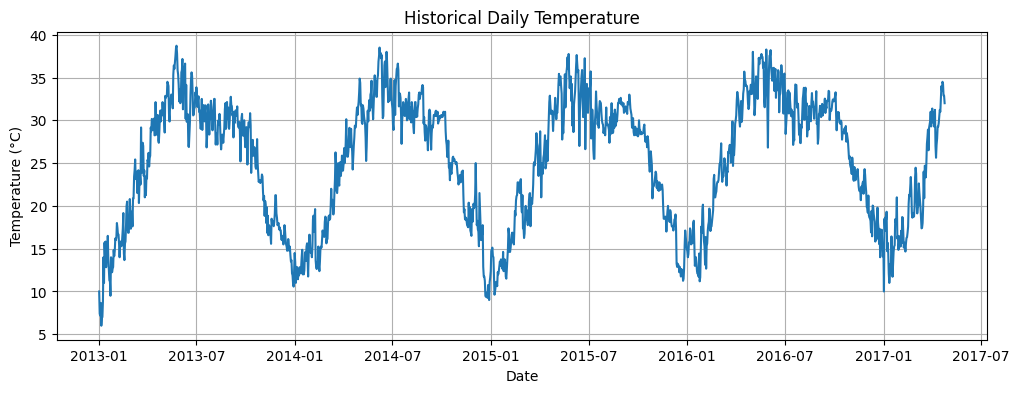

Normalization completed!


In [ ]:

features = [
    'meantemp',
    'humidity',
    'wind_speed',
    'meanpressure'
]

# Convert columns to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Replace invalid and infinite values
df[features] = df[features].replace(
    [np.inf, -np.inf], np.nan
)

# Remove unrealistic atmospheric pressure values
df.loc[
    (df['meanpressure'] < 800) |
    (df['meanpressure'] > 1100),
    'meanpressure'
] = np.nan

# Fill missing values
df[features] = df[features].interpolate(
    limit_direction='both'
)

df = df.dropna(subset=features).reset_index(drop=True)

# Check consecutive dates
gaps = df['date'].diff().dt.days
print("Valid records:", len(df))
print("Date gaps:", (gaps > 1).sum())
print("Missing values:\n", df[features].isnull().sum())

# Plot historical temperature
plt.figure(figsize=(12, 4))
plt.plot(df['date'], df['meantemp'])
plt.title('Historical Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

# Normalize the features
split = int(len(df) * 0.8)
sequence_length = 30

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(df[features].iloc[:split])
target_scaler.fit(df[['meantemp']].iloc[:split])

X_scaled = feature_scaler.transform(df[features])
y_scaled = target_scaler.transform(df[['meantemp']])

print("Normalization completed!")


In [ ]:

X, y, indices = [], [], []

for i in range(sequence_length, len(df)):
    X.append(X_scaled[i-sequence_length:i])
    y.append(y_scaled[i, 0])
    indices.append(i)

X = np.array(X)
y = np.array(y)
indices = np.array(indices)

# Split by date, not randomly
train_mask = indices < split
test_mask = indices >= split

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)

# Build the LSTM model
model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(sequence_length, len(features))),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("Model training completed!")


Training sequences: (1230, 30, 4)
Testing sequences: (315, 30, 4)
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0739 - val_loss: 0.0066
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0131 - val_loss: 0.0039
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 0.0070 - val_loss: 0.0060
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0065 - val_loss: 0.0065
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0061 - val_loss: 0.0073
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0061 - val_loss: 0.0066
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0061 - val_loss: 0.0068
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0059 - val_loss: 0.0060
Epoch 9/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0066 - val_loss: 0.0061
Epoch 10/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0076 - val_loss: 0.0051
Epoch 11/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0076 - val_loss: 0.0060
Epoch 12/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0086 - val_l

In [ ]:

# Predict temperatures
pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions back to Celsius
actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predicted = target_scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 3), "°C")
print("RMSE:", round(rmse, 3), "°C")


MAE: 1.878 °C
RMSE: 2.331 °C


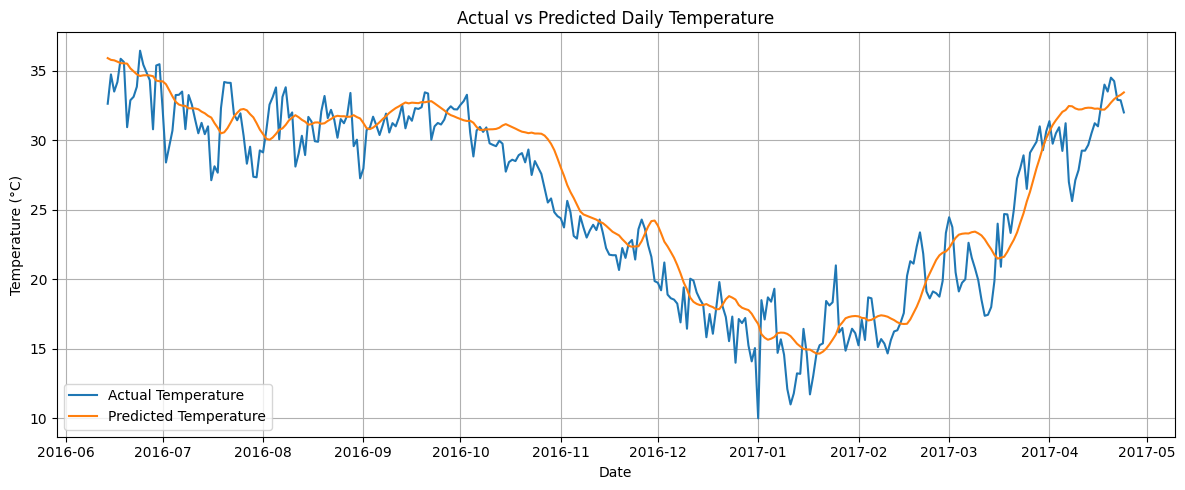

In [ ]:

test_dates = df['date'].iloc[indices[test_mask]]

plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual, label='Actual Temperature')
plt.plot(test_dates, predicted, label='Predicted Temperature')

plt.title('Actual vs Predicted Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Next 7 Days Temperature Forecast
      Date  Predicted Temperature (°C)
2017-04-25                       33.58
2017-04-26                       33.77
2017-04-27                       33.97
2017-04-28                       34.19
2017-04-29                       34.40
2017-04-30                       34.62
2017-05-01                       34.84


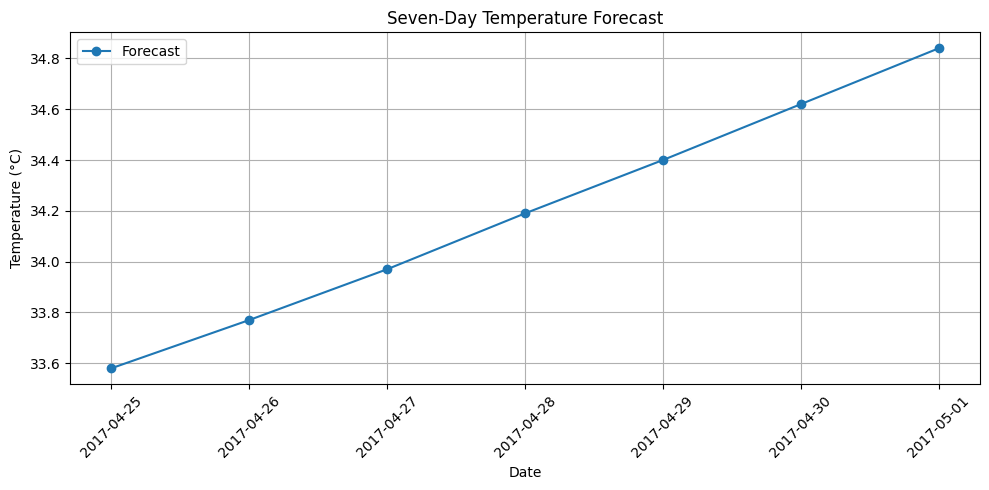

In [ ]:

recent = X_scaled[-sequence_length:].copy()
last_date = df['date'].iloc[-1]
last_weather = df[features].iloc[-1].copy()

forecast = []

for day in range(1, 8):
    # Predict the next day's temperature
    next_scaled = model.predict(
        recent.reshape(1, sequence_length, len(features)),
        verbose=0
    )

    next_temp = target_scaler.inverse_transform(
        next_scaled
    )[0, 0]

    future_date = last_date + pd.Timedelta(days=day)

    forecast.append({
        'Date': future_date,
        'Predicted Temperature (°C)': round(float(next_temp), 2)
    })

    # Update the sequence for the next prediction
    next_row = last_weather.copy()
    next_row['meantemp'] = next_temp

    next_input = feature_scaler.transform(
        pd.DataFrame([next_row], columns=features)
    )

    recent = np.vstack([recent[1:], next_input])

forecast_df = pd.DataFrame(forecast)

print("Next 7 Days Temperature Forecast")
print(forecast_df.to_string(index=False))

# Plot the forecast
plt.figure(figsize=(10, 5))
plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted Temperature (°C)'],
    marker='o',
    label='Forecast'
)
plt.title('Seven-Day Temperature Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


----- Weather Forecasting Results -----
MAE: 1.88 °C
RMSE: 2.33 °C
Approximate Accuracy: 92.65 %

Actual vs Predicted Temperature:
Actual: 32.62 °C | Predicted: 35.9 °C
Actual: 34.73 °C | Predicted: 35.78 °C
Actual: 33.5 °C | Predicted: 35.75 °C
Actual: 34.19 °C | Predicted: 35.65 °C
Actual: 35.86 °C | Predicted: 35.54 °C
Actual: 35.62 °C | Predicted: 35.53 °C
Actual: 30.94 °C | Predicted: 35.51 °C
Actual: 32.88 °C | Predicted: 35.17 °C
Actual: 33.12 °C | Predicted: 34.95 °C
Actual: 33.85 °C | Predicted: 34.74 °C


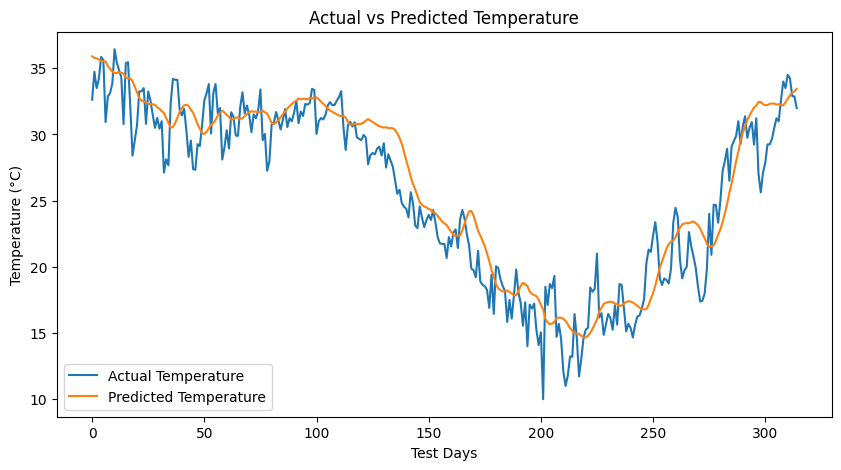

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Predict temperature
pred_scaled = model.predict(X_test, verbose=0)

# Convert values to Celsius
predicted = target_scaler.inverse_transform(pred_scaled)
actual = target_scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
accuracy = max(0, 100 * (1 - mae / np.mean(np.abs(actual))))

print("----- Weather Forecasting Results -----")
print("MAE:", round(mae, 2), "°C")
print("RMSE:", round(rmse, 2), "°C")
print("Approximate Accuracy:", round(accuracy, 2), "%")

print("\nActual vs Predicted Temperature:")
for i in range(min(10, len(actual))):
    print("Actual:", round(actual[i][0], 2), "°C",
          "| Predicted:", round(predicted[i][0], 2), "°C")

# Plot results
plt.figure(figsize=(10, 5))
plt.plot(actual, label="Actual Temperature")
plt.plot(predicted, label="Predicted Temperature")
plt.xlabel("Test Days")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Predicted Temperature")
plt.legend()
plt.show()


In [ ]:

# User Input: Enter today's weather details

temperature = float(input("Enter today's temperature (°C): "))
humidity = float(input("Enter today's humidity (%): "))
wind_speed = float(input("Enter today's wind speed: "))
meanpressure = float(input("Enter today's atmospheric pressure: "))

# Store the input values
new_weather = pd.DataFrame([{
    'meantemp': temperature,
    'humidity': humidity,
    'wind_speed': wind_speed,
    'meanpressure': meanpressure
}])[features]

# Use the previous 29 days and today's input
last_29_days = X_scaled[-29:]
today_scaled = feature_scaler.transform(new_weather)

input_sequence = np.vstack([
    last_29_days,
    today_scaled
])

# Predict tomorrow's temperature
prediction_scaled = model.predict(
    input_sequence.reshape(1, 30, len(features)),
    verbose=0
)

predicted_temperature = target_scaler.inverse_transform(
    prediction_scaled
)[0, 0]

print("\n--- Temperature Forecast Result ---")
print("Today's temperature:", temperature, "°C")
print("Predicted next-day temperature:",
      round(float(predicted_temperature), 2), "°C")


Enter today's temperature (°C): 30
Enter today's humidity (%): 65
Enter today's wind speed: 1200
Enter today's atmospheric pressure: 1001

--- Temperature Forecast Result ---
Today's temperature: 30.0 °C
Predicted next-day temperature: 35.05 °C
